In [54]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

from mpl_toolkits.basemap import Basemap
import networkx as nx

In [2]:
%run Data_processing.py

In [3]:
df_interactions = pd.read_excel('../../../Data/Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions')

In [122]:
df_interactions

,Source,Target,Response,Strength,min,max
0,GIS,AMOC,Destabilising,Strong,0.1,10.0
1,WAIS,AMOC,Unclear,"Weak, Moderate",-3.0,3.0
2,AMOC,GIS,Stabilising,Strong,-10.0,-0.1
3,AMOC,WAIS,Destabilising,Unclear,0.1,1.5
4,GIS,WAIS,Destabilising,Moderate,0.1,5.0
5,WAIS,GIS,Destabilising,Weak,0.1,2.0
6,ASI,AMOC,Destabilising,"Weak, Moderate",0.1,3.0
7,AMOC,ASI,Stabilising,"Weak, Moderate",-3.0,-0.1
8,ASI,GIS,Destabilising,Weak,0.1,2.0
9,ASI,PERM,Destabilising,Weak,0.1,2.0


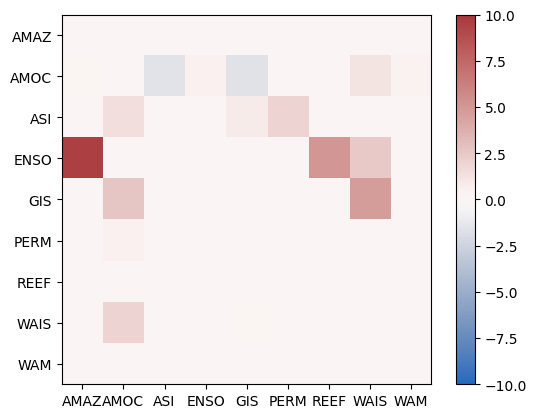

In [5]:
fig,ax=plt.subplots()
im=ax.imshow(A[100],vmin=-10,vmax=10,cmap='vlag')
ax.set_xticks(range(A[0].shape[0]), df_TEs.index.values)
ax.set_yticks(range(A[0].shape[0]), df_TEs.index.values)
plt.colorbar(im)

In [4]:
G = nx.from_pandas_edgelist(df_interactions,source='Source',target='Target',edge_attr=['min', 'max'],create_using=nx.DiGraph)
m = Basemap(projection='kav7',lon_0=-30,resolution='c',)
            # llcrnrlat=-80,urcrnrlat=80,llcrnrlon=-180,urcrnrlon=180,lat_ts=20,);
pos_lonlat = {'GIS':[-43,75], 'AMOC':[-30,40],'ENSO':[-115,-8.8],
              'WAIS':[-90,-75],'ASI':[0,68],'PERM':[70,60],
              'WAM':[0,15],'REEF':[-80,12],'AMAZ':[-62.2,-3.5]}
pos_xy ={k:m(v[0],v[1]) for k,v in pos_lonlat.items()}
T_lim_dic = df_TEs['Threshold (°C) – Est.'].to_dict()

In [5]:
elist = [(e[0],e[1],0) for e in G.edges]
earc_dic = {e:0 for e in G.edges}
earc_dic[('GIS','AMOC')]=0.2
earc_dic[('AMOC','GIS')]=0.2
earc_dic[('AMOC','WAIS')]=-0.5
earc_dic[('AMOC','ENSO')]=0.3
earc_dic[('WAIS','AMOC')]=0.3
earc_dic[('ASI','AMOC')]=0.15
earc_dic[('AMOC','ASI')]=0.15
earc_dic[('ASI','GIS')]=0.1
earc_dic[('PERM','AMOC')]=-0.15
earc_dic[('ASI','PERM')]=-0.1
earc_dic[('PERM','ASI')]=-0.1
earc_dic[('WAIS','GIS')]=-0.9
earc_dic[('GIS','WAIS')]=1.4

For automatic curved edges check out netgraph: \
https://stackoverflow.com/questions/52588453/drawing-curved-edges-with-networkx-in-python \
https://github.com/paulbrodersen/netgraph/tree/master

## designing the network subpanel

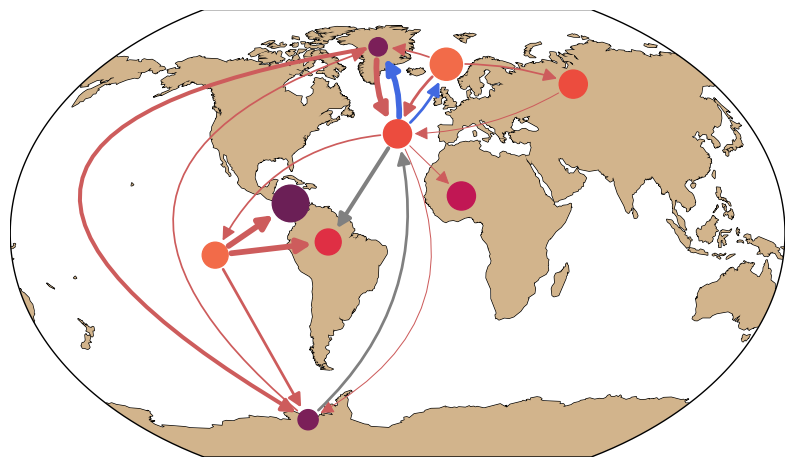

In [128]:
fig,ax=plt.subplots(figsize=(10,8))

m.fillcontinents(color='tan',lake_color='tan',ax=ax,zorder=1);
m.drawcoastlines(color='k',zorder=0)

node_cmap = 'rocket'
vmin = -1
vmax = 7 
node_size=[1600/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes]
nx.draw_networkx(G,ax=ax,pos=pos_xy,
                 node_size=node_size,with_labels=False,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=vmin,vmax=vmax,cmap=node_cmap,
                 font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'indianred'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'royalblue'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.8,
                           node_size=[n+200 for n in node_size],
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])),
                           arrowsize=20
                          );

# ax_leg = fig.add_axes((0.65,0.23,0.25,0.2))
# ax_leg.set_xticks([])
# ax_leg.set_yticks([])

# size_disp = [10,100,1000,10000]
# ax_leg.scatter(np.log10(size_disp),[0]*len(size_disp),s=[1600/np.log(s) for s in size_disp])
# ax_leg.set_xlim(0,1+len(size_disp))

## Critical thresholds

In [132]:
df_TEs_sorted = df_TEs.sort_values(by=["Threshold (°C) – Min."])

(-1.0, 9.0)

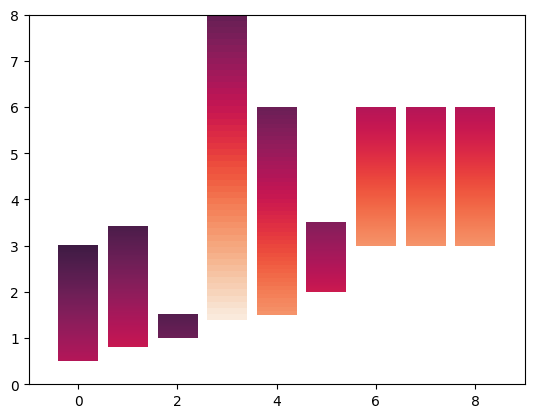

In [176]:
fig,ax=plt.subplots()
te_sorted = df_TEs_sorted.index.values
tps = df_TEs_sorted[['Threshold (°C) – Min.','Threshold (°C) – Est.','Threshold (°C) – Max.']].to_numpy()
ax.bar(np.arange(9),[z-x for x,y,z in tps],bottom=[x for x,y,z in tps])
ax.set_ylim(0,8)

for i,v in enumerate(tps):
    x,y,z=v
    ax.imshow(np.atleast_2d(np.linspace(x,z)).T, extent=[i-0.4,i+0.4,x,z], aspect="auto", 
              zorder=1,vmin=-1,vmax=8,cmap=node_cmap)

ax.set_xlim(-1,9)

In [172]:
print(z)

6.0


In [177]:
print(np.linspace(x,z))

[3.         3.06122449 3.12244898 3.18367347 3.24489796 3.30612245
 3.36734694 3.42857143 3.48979592 3.55102041 3.6122449  3.67346939
 3.73469388 3.79591837 3.85714286 3.91836735 3.97959184 4.04081633
 4.10204082 4.16326531 4.2244898  4.28571429 4.34693878 4.40816327
 4.46938776 4.53061224 4.59183673 4.65306122 4.71428571 4.7755102
 4.83673469 4.89795918 4.95918367 5.02040816 5.08163265 5.14285714
 5.20408163 5.26530612 5.32653061 5.3877551  5.44897959 5.51020408
 5.57142857 5.63265306 5.69387755 5.75510204 5.81632653 5.87755102
 5.93877551 6.        ]


In [161]:
for i,v in enumerate(tps):
    print(i,v[0])

0 0.5
1 0.8
2 1.0
3 1.4
4 1.5
5 2.0
6 3.0
7 3.0
8 3.0


In [148]:
tps

array([[0.5, 1.5, 3. ],
       [0.8, 1.5, 3.4],
       [1. , 1.2, 1.5],
       [1.4, 4. , 8. ],
       [1.5, 3.5, 6. ],
       [2. , 2.8, 3.5],
       [3. , 4.5, 6. ],
       [3. , 4.5, 6. ],
       [3. , 4. , 6. ]])

In [147]:
[z-x for x,y,z in tps]

[np.float64(2.5),
 np.float64(2.5999999999999996),
 np.float64(0.5),
 np.float64(6.6),
 np.float64(4.5),
 np.float64(1.5),
 np.float64(3.0),
 np.float64(3.0),
 np.float64(3.0)]

# All together

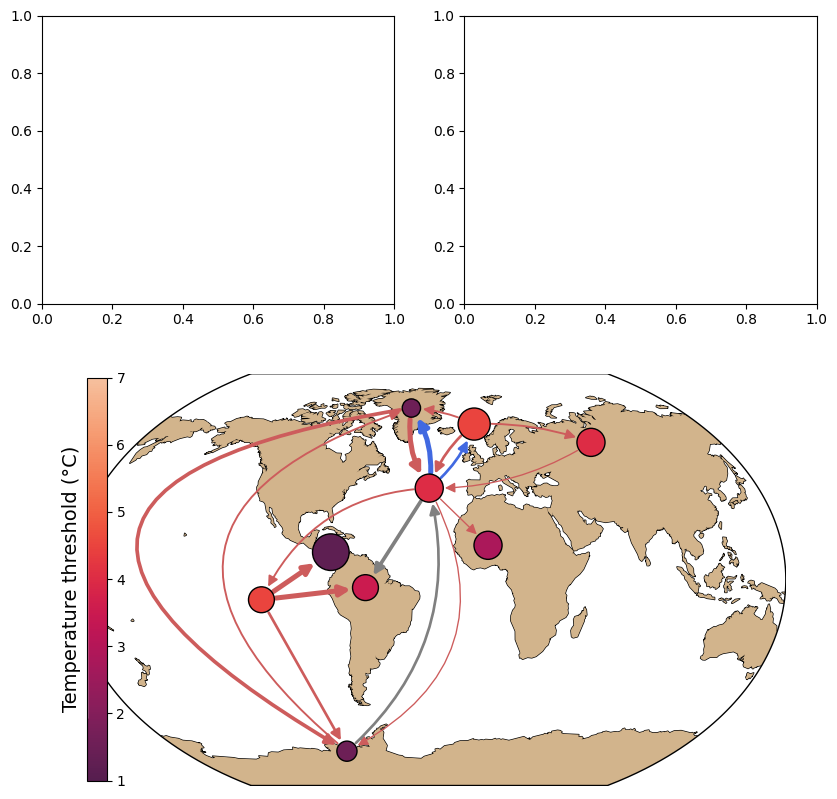

In [155]:
fig = plt.figure(figsize=(10,10))
gs = GridSpec(2, 2, figure=fig,height_ratios=[1.4,2])
ax1= fig.add_subplot(gs[0,0])
ax2= fig.add_subplot(gs[0,1])
ax3= fig.add_subplot(gs[1,0:])

m.fillcontinents(color='tan',lake_color='tan',ax=ax3,zorder=1);
m.drawcoastlines(color='k',zorder=0)

node_cmap = 'rocket'
vmin = -1
vmax = 8 
node_size=[1600/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes]
im = nx.draw_networkx(G,ax=ax3,pos=pos_xy,
                 node_size=node_size,
                 with_labels=False,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 edgecolors='k',
                 vmin=vmin,vmax=vmax,cmap=node_cmap,
                 font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'indianred'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'royalblue'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax3,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.4+0.4,
                           node_size=[n+100 for n in node_size],
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])),
                           arrowsize=15
                          );
# fig.colorbar(im,ax=ax3)
# m.drawcoastlines(ax=ax3)
# m.drawlsmask()

cax = fig.add_axes((0.17,0.115, 0.02,0.685*2/3.4))
colorizer = mpl.colorizer.Colorizer(norm=mpl.colors.Normalize(vmin, vmax), cmap=node_cmap)
cb = fig.colorbar(mpl.colorizer.ColorizingArtist(colorizer), 
                  cax=cax,orientation='vertical')
cb.set_label(label='Temperature threshold (°C)',size=14,backgroundcolor='white')
cax.set_ylim(1,7)
cax.yaxis.set_label_position('left')

# Testing netgraph for visualisation

In [9]:
from netgraph import Graph

In [40]:
print(m(0,0))
print(m(-150,0))
print(m(210,0))

(19719303.91295753, 8451130.2484144)
(5634086.832266869, 8451130.2484144)
(5634086.832266871, 8451130.2484144)


TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'

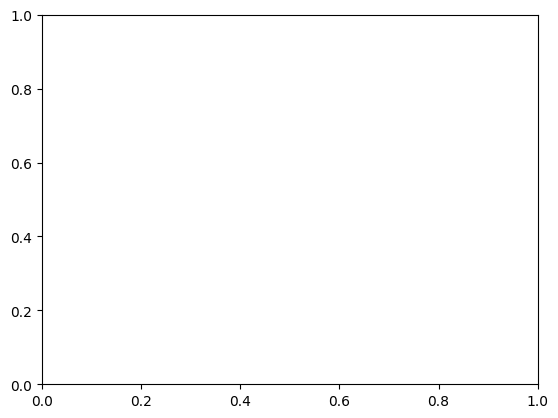

In [43]:
fig,ax=plt.subplots()
xmax = max([v[0] for k,v in pos_xy.items()])
ymax = max([v[1] for k,v in pos_xy.items()])
Graph(G, 
      node_layout={k:(v[0]/xmax,v[1]/ymax) for k,v in pos_xy.items()},
      ax=ax,edge_layout='curved')

In [20]:
print({k:(v[0]/360,v[1]/360) for k,v in pos_lonlat.items()})

{'GIS': (-0.11944444444444445, 0.19444444444444445), 'AMOC': (-0.08333333333333333, 0.11944444444444445), 'ENSO': (-0.3611111111111111, -0.024444444444444446), 'WAIS': (-0.25, -0.20833333333333334), 'ASI': (0.013888888888888888, 0.19444444444444445), 'PERM': (0.2777777777777778, 0.16666666666666666), 'WAM': (0.03888888888888889, 0.05416666666666667), 'REEF': (-0.2222222222222222, 0.03333333333333333), 'AMAZ': (-0.17277777777777778, -0.009722222222222222)}
